In [1]:
import sys
from pathlib import Path
import pickle

import cv2 as cv
import numpy as np
import open3d as o3d

ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"
PROCESSED_DIR = ROOT_DIR / "data/processed"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"

from src.reconstruction import (
    create_stereo_matcher,
    compute_disparities,
    merge_global_point_cloud,
    build_local_point_cloud,
    create_charuco_detector,
    estimate_global_pose,
)
from src.calibration_rectification import rectify_image_pair
from src.utils.utils import indexed_images, get_image_at_index
from src.utils.prints import print_matrix
from src.utils.plotting import (
    show_disparity,
    show_geometries,
    save_open3d_screenshot,
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# 1. Stereo Matching

In [2]:
# Mapas exportados por el notebook 01.
dataset_name = "palacio"
dataset_dir = ROOT_DIR / "data/raw" / dataset_name
dataset_output_dir = PROCESSED_DIR / dataset_name
disparity_dir = dataset_output_dir / "disparity"
disparity_dir.mkdir(parents=True, exist_ok=True)

with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as stream:
    maps = pickle.load(stream)
left_rectification_map_x = np.asarray(maps["left_map_x"])
left_rectification_map_y = np.asarray(maps["left_map_y"])
right_rectification_map_x = np.asarray(maps["right_map_x"])
right_rectification_map_y = np.asarray(maps["right_map_y"])

In [3]:
left_by_index = indexed_images(dataset_dir, "left")
right_by_index = indexed_images(dataset_dir, "right")
pair_ids = sorted(left_by_index)
images_left = [str(left_by_index[index]) for index in pair_ids]
images_right = [str(right_by_index[index]) for index in pair_ids]

Disparidades guardadas en palacio\disparity (72 pares)


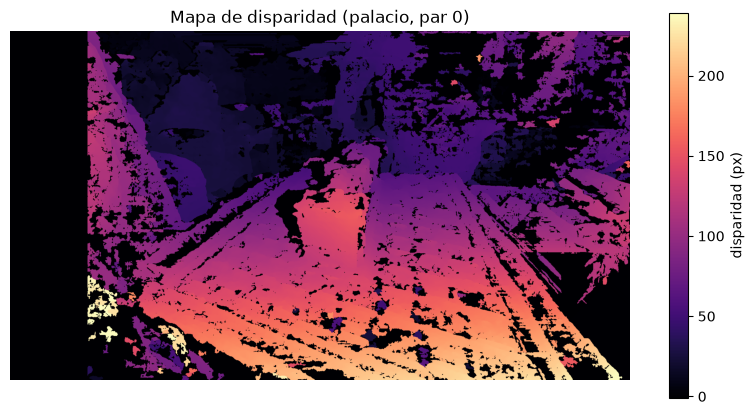

In [4]:
block_size = 11
min_disparity, num_disparities = 0, 240
stereo = create_stereo_matcher(
    min_disparity=min_disparity,
    num_disparities=num_disparities,
    block_size=block_size,
)
compute_disparities(
    images_left,
    images_right,
    stereo,
    left_rectification_map_x,
    left_rectification_map_y,
    right_rectification_map_x,
    right_rectification_map_y,
    str(disparity_dir),
)
print(
    f"Disparidades guardadas en {disparity_dir.relative_to(PROCESSED_DIR)} ({len(pair_ids)} pares)"
)

disparity_example = np.load(disparity_dir / "disp_0.npy")
show_disparity(
    disparity_example,
    title=f"Mapa de disparidad ({dataset_name}, par 0)",
    save_path=REPORT_IMAGES_DIR / f"disparidad_{dataset_name}.png",
)

# 2. Computar Nube local

In [5]:
Q = np.asarray(maps["Q"])
Z_MIN, Z_MAX = 100.0, 2000.0

disparity_0 = np.load(disparity_dir / "disp_0.npy")
point_cloud_0 = build_local_point_cloud(
    str(left_by_index[0]),
    disparity_0,
    Q,
    left_rectification_map_x,
    left_rectification_map_y,
    min_disparity=min_disparity,
    z_min=Z_MIN,
    z_max=Z_MAX,
)
print(f"Nube local del par 0: {len(point_cloud_0.points):,} puntos")
show_geometries([point_cloud_0], title=f"Nube local - par 0 ({dataset_name})")

Nube local del par 0: 1,113,994 puntos


# 3. Pose global

In [6]:
rectified_intrinsic = np.asarray(maps["P1"])[:3, :3]
charuco_board, charuco_detector = create_charuco_detector()

img_left, img_right = get_image_at_index(dataset_name=dataset_name, index=0)
rect_left, _ = rectify_image_pair(img_left, img_right, maps)
camera_to_world_transform_0 = estimate_global_pose(
    cv.cvtColor(rect_left, cv.COLOR_BGR2GRAY),
    charuco_detector,
    charuco_board,
    rectified_intrinsic,
)
if camera_to_world_transform_0 is None:
    print("No se detectó el tablero en el par 0.")
else:
    print_matrix(
        "Pose del par 0 (cámara rectificada → mundo)", camera_to_world_transform_0
    )
    print(
        f"Posición de la cámara en el mundo: {np.round(camera_to_world_transform_0[:3, 3], 1)} mm"
    )

0.911954,0.114162,-0.39409,244.942
-0.405684,0.394445,-0.82452,692.793
0.0613176,0.911801,0.406029,-220.99
0,0,0,1


Posición de la cámara en el mundo: [ 244.9  692.8 -221. ] mm


# 4. Transformación

In [7]:
global_point_cloud, camera_frames, merged_pair_count, discarded_pair_count = (
    merge_global_point_cloud(
        images_left,
        str(disparity_dir),
        Q,
        left_rectification_map_x,
        left_rectification_map_y,
        charuco_detector,
        charuco_board,
        rectified_intrinsic,
        min_disparity=min_disparity,
        z_min=Z_MIN,
        z_max=Z_MAX,
    )
)
print(
    f"Pares fusionados: {merged_pair_count} | descartados sin tablero: {discarded_pair_count}"
)
print(f"Puntos en la nube global: {len(global_point_cloud.points):,}")

global_point_cloud_path = dataset_output_dir / f"nube_global_{dataset_name}.ply"
if not o3d.io.write_point_cloud(str(global_point_cloud_path), global_point_cloud):
    raise OSError(f"No se pudo guardar {global_point_cloud_path}")
print("Nube global guardada en", global_point_cloud_path)

world_origin = o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)
scene_geometries = [global_point_cloud, world_origin, *camera_frames]
save_open3d_screenshot(
    scene_geometries, str(REPORT_IMAGES_DIR / f"poses_{dataset_name}.png")
)
show_geometries(
    scene_geometries, title=f"Nube global en el marco de mundo ({dataset_name})"
)

Pares fusionados: 71 | descartados sin tablero: 1
Puntos en la nube global: 87,150,016
Nube global guardada en c:\Users\Usuario\OneDrive\Documentos\UdeSA cursos de ingreso 2023\udesa ingenieria en IA\carrera\3°er año ingenieria en IA\2°do semestre\vision artificial\TPs\Vision-Artificial-TP2\data\processed\palacio\nube_global_palacio.ply
